<a href="https://colab.research.google.com/github/bharatsharma2222/stats_practicals/blob/main/Practical9.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    classification_report
)

# Load Iris dataset
iris = load_iris()

df = pd.DataFrame(iris.data, columns=iris.feature_names)
df['species'] = iris.target

# Convert numeric labels into species names
df['species'] = df['species'].map({
    0: 'setosa',
    1: 'versicolor',
    2: 'virginica'
})

print(df.head())

   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)  \
0                5.1               3.5                1.4               0.2   
1                4.9               3.0                1.4               0.2   
2                4.7               3.2                1.3               0.2   
3                4.6               3.1                1.5               0.2   
4                5.0               3.6                1.4               0.2   

  species  
0  setosa  
1  setosa  
2  setosa  
3  setosa  
4  setosa  


**EDA (Exploratory Data Analysis)**

In [ ]:
print(df.head())

   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)  \
0                5.1               3.5                1.4               0.2   
1                4.9               3.0                1.4               0.2   
2                4.7               3.2                1.3               0.2   
3                4.6               3.1                1.5               0.2   
4                5.0               3.6                1.4               0.2   

  species  
0  setosa  
1  setosa  
2  setosa  
3  setosa  
4  setosa  


In [ ]:
print(df.describe())

       sepal length (cm)  sepal width (cm)  petal length (cm)  \
count         150.000000        150.000000         150.000000   
mean            5.843333          3.057333           3.758000   
std             0.828066          0.435866           1.765298   
min             4.300000          2.000000           1.000000   
25%             5.100000          2.800000           1.600000   
50%             5.800000          3.000000           4.350000   
75%             6.400000          3.300000           5.100000   
max             7.900000          4.400000           6.900000   

       petal width (cm)  
count        150.000000  
mean           1.199333  
std            0.762238  
min            0.100000  
25%            0.300000  
50%            1.300000  
75%            1.800000  
max            2.500000  


In [ ]:
print(df.groupby('species').size())

species
setosa        50
versicolor    50
virginica     50
dtype: int64


In [ ]:
print(df.isnull().sum())

sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
species              0
dtype: int64


**Feature scaling**

In [ ]:
# Separate features and target
X = df.drop('species', axis=1)
y = iris.target

# Split into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Apply feature scaling
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)

Training data shape: (120, 4)
Testing data shape: (30, 4)


**Training the KNN model**

In [ ]:
# Create KNN model
knn = KNeighborsClassifier(n_neighbors=5)

# Train the model
knn.fit(X_train, y_train)

# Predict test results
y_pred = knn.predict(X_test)

print("Predicted values:", y_pred)
print("Actual values:   ", y_test)

Predicted values: [0 2 1 1 0 1 0 0 2 1 2 2 2 1 0 0 0 1 1 1 0 2 1 1 2 1 1 0 2 0]
Actual values:    [0 2 1 1 0 1 0 0 2 1 2 2 2 1 0 0 0 1 1 2 0 2 1 2 2 1 1 0 2 0]


**Confusion matrix and accuracy score**

Confusion Matrix:
[[10  0  0]
 [ 0 10  0]
 [ 0  2  8]]
Accuracy Score: 0.9333333333333333
Accuracy Percentage: 93.33333333333333 %


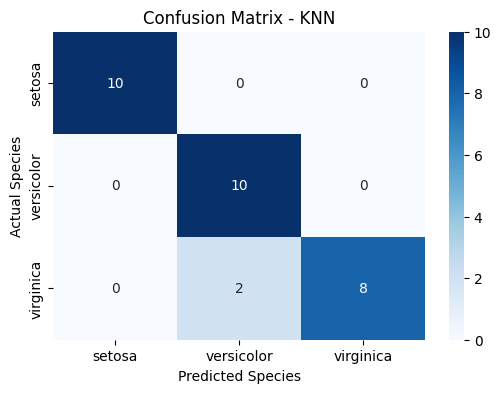

In [ ]:
# Confusion matrix
cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

# Accuracy
accuracy = accuracy_score(y_test, y_pred)

print("Accuracy Score:", accuracy)
print("Accuracy Percentage:", accuracy * 100, "%")

# Plot confusion matrix
plt.figure(figsize=(6, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=iris.target_names,
    yticklabels=iris.target_names
)

plt.xlabel("Predicted Species")
plt.ylabel("Actual Species")
plt.title("Confusion Matrix - KNN")
plt.show()

**Conclusion:
The confusion matrix shows that the KNN model achieved an accuracy of 93.33%. It correctly classified all 10 Setosa flowers and all 10 Versicolor flowers. Out of 10 Virginica flowers, 8 were correctly classified, while 2 were incorrectly classified as Versicolor. Therefore, the KNN model performs well on the Iris dataset, with only 2 incorrect predictions out of 30 test samples.**

**Classification report**

In [ ]:
print("Classification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=iris.target_names
))

Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.83      1.00      0.91        10
   virginica       1.00      0.80      0.89        10

    accuracy                           0.93        30
   macro avg       0.94      0.93      0.93        30
weighted avg       0.94      0.93      0.93        30



**Comparing error rate with different K values**

In [ ]:
error_rate = []

for k in range(1, 21):
    model = KNeighborsClassifier(n_neighbors=k)
    model.fit(X_train, y_train)

    predictions = model.predict(X_test)

    error = np.mean(predictions != y_test)
    error_rate.append(error)

# Display error rates
for k, error in enumerate(error_rate, start=1):
    print(f"K = {k}, Error Rate = {error:.4f}")

K = 1, Error Rate = 0.0333
K = 2, Error Rate = 0.0667
K = 3, Error Rate = 0.0667
K = 4, Error Rate = 0.0667
K = 5, Error Rate = 0.0667
K = 6, Error Rate = 0.0667
K = 7, Error Rate = 0.0333
K = 8, Error Rate = 0.0667
K = 9, Error Rate = 0.0333
K = 10, Error Rate = 0.0333
K = 11, Error Rate = 0.0333
K = 12, Error Rate = 0.0333
K = 13, Error Rate = 0.0333
K = 14, Error Rate = 0.0333
K = 15, Error Rate = 0.0333
K = 16, Error Rate = 0.0333
K = 17, Error Rate = 0.0333
K = 18, Error Rate = 0.0333
K = 19, Error Rate = 0.0333
K = 20, Error Rate = 0.0333


**Plot error values against K values**

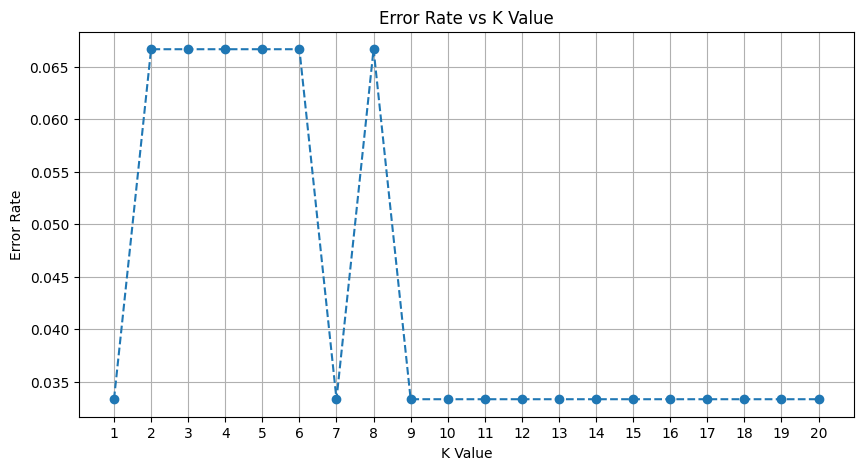

In [ ]:
plt.figure(figsize=(10, 5))

plt.plot(
    range(1, 21),
    error_rate,
    marker='o',
    linestyle='--'
)

plt.xlabel("K Value")
plt.ylabel("Error Rate")
plt.title("Error Rate vs K Value")
plt.xticks(range(1, 21))
plt.grid(True)
plt.show()

**The graph shows the relationship between the K value and the error rate in the KNN model. The minimum error rate is approximately 0.0333 (3.33%), observed at \(K=1\) and \(K=7\), and again for \(K=9\) to \(K=20\). The error rate is higher, approximately 6.67%, for several values between \(K=2\) and \(K=8\). Therefore, the model performs well for multiple K values. Based on this graph, \(K=9\) is a reasonable choice because it achieves the minimum error rate with more neighbors than \(K=1\), which may help reduce sensitivity to noise.**

**Finding the best K**

In [ ]:
# Find K with minimum test error
best_k = np.argmin(error_rate) + 1
minimum_error = min(error_rate)

print("Best K Value:", best_k)
print("Minimum Error Rate:", minimum_error)
print("Best Accuracy:", (1 - minimum_error) * 100, "%")

Best K Value: 1
Minimum Error Rate: 0.03333333333333333
Best Accuracy: 96.66666666666667 %


**Visualize the KNN test results**

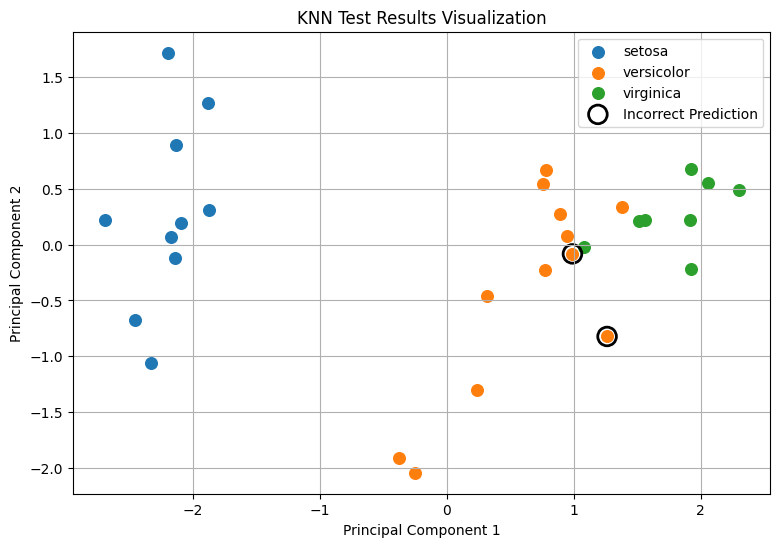

In [ ]:
from sklearn.decomposition import PCA

# Reduce test data to 2 dimensions for visualization
pca = PCA(n_components=2)
X_test_2d = pca.fit_transform(X_test)

# Plot predicted classes
plt.figure(figsize=(9, 6))

for i, name in enumerate(iris.target_names):
    mask = y_pred == i

    plt.scatter(
        X_test_2d[mask, 0],
        X_test_2d[mask, 1],
        label=name,
        s=70
    )

# Highlight incorrectly classified samples
wrong = y_pred != y_test

plt.scatter(
    X_test_2d[wrong, 0],
    X_test_2d[wrong, 1],
    facecolors='none',
    edgecolors='black',
    s=180,
    linewidths=2,
    label='Incorrect Prediction'
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("KNN Test Results Visualization")
plt.legend()
plt.grid(True)
plt.show()

**Conclusion:

The graph shows the relationship between the K value and the error rate in the KNN model. The minimum error rate is approximately 0.0333 (3.33%), observed at \\(K=1\\) and \\(K=7\\), and again for \\(K=9\\) to \\(K=20\\). The error rate is higher, approximately 6.67%, for several values between \\(K=2\\) and \\(K=8\\). Therefore, the model performs well for multiple K values. Based on this graph, \\(K=9\\) is a reasonable choice because it achieves the minimum error rate with more neighbors than \\(K=1\\), which may help reduce sensitivity to noise.**